# 00 — Data Understanding: sources and quality

CRISP-DM phase 2. This notebook describes **where the data comes from** and **how good it is**, and checks what the cleaning step (`src/sp500/data_prep.py`) changes.

It reads the raw snapshot in `data/raw/` and needs no internet connection. The figures are saved to `docs/figures/`, and the written summary is in [`docs/02_data_understanding.md`](../docs/02_data_understanding.md).

| Section | Question |
|---|---|
| 1. Sources | What is each dataset, where does it come from, and which fields are really available when? |
| 2. Quality: raw data | Is it complete and valid? Are the extreme values real, or bad prints? |
| 3. Quality: cross-source consistency | Do the four sources agree with each other? |
| 4. Effect of cleaning | What did cleaning change, and what is usable afterwards? |
| 5. Conclusions | What this means for the next phases |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from sp500.config import TICKERS
from sp500.data_prep import build_dataset, load_raw

FIG = ROOT / 'docs' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)
pd.set_option('display.max_columns', 30)

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=110, bbox_inches='tight')

NAMES = {'gspc': 'S&P 500 price index', 'sp500tr': 'S&P 500 total return index',
         'spy': 'SPY ETF', 'es': 'E-mini S&P 500 futures'}
raw = {n: load_raw(n) for n in NAMES}          # as downloaded
daily, quality = build_dataset()               # cleaned + aligned on the ^GSPC calendar
CAL = raw['gspc'].index                        # NYSE trading calendar (master)
print('raw series loaded:', {n: len(df) for n, df in raw.items()})
print('cleaned/aligned table:', daily.shape)

[fix] 4 suspected bad prints in gspc_close replaced: 1935-04-16, 1935-08-16, 1936-09-16, 1961-04-17
raw series loaded: {'gspc': 24821, 'sp500tr': 9776, 'spy': 8492, 'es': 6590}
cleaned/aligned table: (24821, 26)


## 1. Sources

All four series were downloaded from **Yahoo Finance** (via its chart API, as `yfinance` does) on 2026-10-25. The data runs through the close of 2026-10-23.

| Series | Ticker | What it is | Owner / original source | Price adjustments |
|---|---|---|---|---|
| S&P 500 price index | `^GSPC` | Market-cap-weighted index of 500 large US companies (90 stocks before March 1957). Excludes dividends | S&P Dow Jones Indices | None. `adj_close` = `close` |
| S&P 500 total return | `^SP500TR` | Same index with dividends reinvested | S&P Dow Jones Indices | None; dividends are already inside the index level |
| SPY | `SPY` | SPDR S&P 500 ETF Trust, the oldest and most traded S&P 500 ETF | State Street Global Advisors (listed on NYSE Arca) | `adj_close` adjusts for dividends; `close` is the raw traded price |
| E-mini S&P 500 | `ES=F` | Continuous front-month futures contract on the S&P 500 | CME Group (Globex) | Yahoo splices contracts at each quarterly roll |

**Access and licensing:** Yahoo data needs no sign-in through the API, but its terms don't allow redistribution, and S&P index values are licensed by S&P Dow Jones Indices (which is why FRED keeps only 10 years). The snapshot in `data/raw/` is for non-commercial academic use. Alternatives: Stooq CSVs (`^spx`, `spy.us`, `es.f`), but Stooq has no total-return index.

In [2]:
sources = pd.DataFrame({
    n: {
        'description': NAMES[n],
        'ticker': TICKERS[n],
        'rows': len(df),
        'first date': df.index.min().date(),
        'last date': df.index.max().date(),
        'years': round((df.index.max() - df.index.min()).days / 365.25, 1),
        'columns': ', '.join(df.columns),
    }
    for n, df in raw.items()
}).T
sources

,description,ticker,rows,first date,last date,years,columns
gspc,S&P 500 price index,^GSPC,24821,1927-12-30,2026-10-23,98.8,"open, high, low, close, adj_close, volume"
sp500tr,S&P 500 total return index,^SP500TR,9776,1988-01-04,2026-10-23,38.8,"open, high, low, close, adj_close, volume"
spy,SPY ETF,SPY,8492,1993-01-29,2026-10-23,33.7,"open, high, low, close, adj_close, volume"
es,E-mini S&P 500 futures,ES=F,6590,2000-09-18,2026-10-23,26.1,"open, high, low, close, adj_close, volume"


### Which fields are really usable, and when?

A column can be present but meaningless. For example, `^GSPC` has open/high/low values back to 1927, but before 1962 they are just copies of the close. The heatmap shows, for each year, the share of trading days on which each field holds real information:

- **close:** non-missing
- **real OHL:** open/high/low not all equal to the close
- **volume:** greater than 0

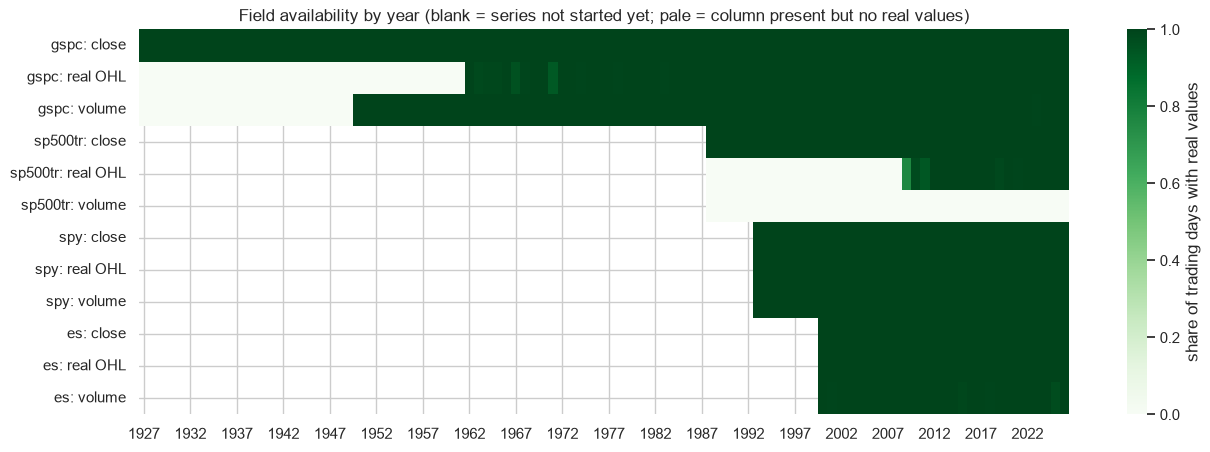

In [3]:
def usable(df):
    flat = (df['open'] == df['high']) & (df['high'] == df['low']) & (df['low'] == df['close'])
    return pd.DataFrame({'close': df['close'].notna(), 'real OHL': ~flat, 'volume': df['volume'] > 0},
                        index=df.index)

cov = {}
for n, df in raw.items():
    u = usable(df).groupby(df.index.year).mean()
    for field in u.columns:
        cov[f'{n}: {field}'] = u[field]
cov = pd.DataFrame(cov).reindex(range(1927, 2027)).T

fig, ax = plt.subplots(figsize=(15, 5))
sns.heatmap(cov, cmap='Greens', vmin=0, vmax=1, xticklabels=5, linewidths=0,
            cbar_kws={'label': 'share of trading days with real values'}, ax=ax)
ax.set_title('Field availability by year (blank = series not started yet; pale = column present but no real values)')
ax.set_xlabel('')
save(fig, 'du_field_availability')

In [4]:
# First date each field becomes reliably available (>= 95% of days in the year)
first_real = (cov.T >= 0.95).idxmax().where((cov.T >= 0.95).any())
first_real.rename('first year with >=95% real values').to_frame()

,first year with >=95% real values
gspc: close,1927.0
gspc: real OHL,1962.0
gspc: volume,1950.0
sp500tr: close,1988.0
sp500tr: real OHL,2010.0
sp500tr: volume,NaN
spy: close,1993.0
spy: real OHL,1993.0
spy: volume,1993.0
es: close,2000.0


## 2. Quality of the raw data

### 2.1 Completeness and calendar

`^GSPC` defines the trading calendar, since it has the longest history. Each other series is compared with it over its own date range.

In [5]:
rows = []
for n, df in raw.items():
    span = CAL[(CAL >= df.index.min()) & (CAL <= df.index.max())]
    rows.append({
        'series': n,
        'rows': len(df),
        'duplicate dates': int(df.index.duplicated().sum()),
        'missing close': int(df['close'].isna().sum()),
        'NYSE days missing': len(span.difference(df.index)) if n != 'gspc' else 0,
        'extra non-NYSE days': len(df.index.difference(CAL)),
    })
completeness = pd.DataFrame(rows).set_index('series')
completeness

,rows,duplicate dates,missing close,NYSE days missing,extra non-NYSE days
series,,,,,
gspc,24821,0,0,0,0
sp500tr,9776,0,0,0,0
spy,8492,0,0,0,0
es,6590,0,0,2,28


In [6]:
es = raw['es']
span = CAL[(CAL >= es.index.min()) & (CAL <= es.index.max())]
print('ES missing on NYSE days :', [d.date() for d in span.difference(es.index)])
extra = es.index.difference(CAL)
print(f'ES extra days ({len(extra)}), e.g.:', [d.strftime('%Y-%m-%d %a') for d in extra[:8]])

ES missing on NYSE days : [datetime.date(2016, 10, 10), datetime.date(2016, 11, 11)]
ES extra days (28), e.g.: ['2001-09-11 Tue', '2002-02-18 Mon', '2002-05-27 Mon', '2002-07-04 Thu', '2002-09-02 Mon', '2002-11-28 Thu', '2003-01-20 Mon', '2003-02-17 Mon']


- **ES extra days:** futures trade a shortened session on many US holidays (Presidents' Day, Memorial Day, July 4th, Thanksgiving, ...) while the NYSE is closed. They are dropped when aligning to the NYSE calendar.
- **ES missing days:** 2016-10-10 (Columbus Day) and 2016-11-11 (Veterans Day). These are gaps in Yahoo's data; the NYSE was open. Cleaning forward-fills them (max 2 days).

In [7]:
# Saturdays: the NYSE traded on Saturdays until 1952
dow = raw['gspc'].index.day_of_week.value_counts().sort_index()
dow.index = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri'][:len(dow)]
print('^GSPC rows by weekday:', dow.to_dict())

# Long breaks in the trading calendar
EVENTS = {
    '1933-03-15': 'Banking crisis: exchanges closed 4-14 March 1933',
    '2001-09-17': '9/11: NYSE closed 11-14 September 2001',
    '2012-10-31': 'Hurricane Sandy: NYSE closed 29-30 October 2012',
    '2007-01-03': 'National day of mourning for President Ford (2 Jan 2007)',
}
g = CAL.to_series().diff().dt.days
gaps = g[g > 4].sort_values(ascending=False).to_frame('calendar days since previous session')
gaps['reason'] = [EVENTS.get(str(d.date()), 'holiday next to a weekend') for d in gaps.index]
gaps

^GSPC rows by weekday: {'Mon': 4773, 'Tue': 5043, 'Wed': 5060, 'Thu': 4983, 'Fri': 4962}


,calendar days since previous session,reason
date,,
1933-03-15,12.0,Banking crisis: exchanges closed 4-14 March 1933
2001-09-17,7.0,9/11: NYSE closed 11-14 September 2001
1929-12-02,5.0,holiday next to a weekend
1945-12-26,5.0,holiday next to a weekend
1958-12-29,5.0,holiday next to a weekend
1956-12-26,5.0,holiday next to a weekend
1961-05-31,5.0,holiday next to a weekend
1968-07-08,5.0,holiday next to a weekend
2007-01-03,5.0,National day of mourning for President Ford (2...


**Findings:**
- There are **no Saturday rows**, although the NYSE held Saturday sessions until 1952. Yahoo's history leaves them out. This is fine for our purposes, but early-period "daily" returns sometimes span a Saturday session.
- Every break longer than 4 calendar days is a known market closure. The longest is the **1933 bank holiday** (12 days). The first session after it (15 March 1933) is also the largest one-day gain in the data (+15.4%), so that return covers 12 days of news, not 1.

### 2.2 Validity

In [8]:
rows = []
for n, df in raw.items():
    p = df[['open', 'high', 'low', 'close']]
    flat = (df['open'] == df['high']) & (df['high'] == df['low']) & (df['low'] == df['close'])
    bad = ((df['high'] < df['low']) | (df['close'] > df['high'] * 1.0001) | (df['close'] < df['low'] * 0.9999)
           | (df['open'] > df['high'] * 1.0001) | (df['open'] < df['low'] * 0.9999))
    rows.append({
        'series': n,
        'non-positive prices': int((p <= 0).sum().sum()),
        'flat OHLC rows (O=H=L=C)': int(flat.sum()),
        'last flat row': flat[flat].index.max().date() if flat.any() else None,
        'OHLC inconsistent rows': int(bad.sum()),
        'zero-volume rows': int((df['volume'] <= 0).sum()),
        'close unchanged vs prior day': int((df['close'].diff() == 0).sum()),
    })
validity = pd.DataFrame(rows).set_index('series')
validity

,non-positive prices,flat OHLC rows (O=H=L=C),last flat row,OHLC inconsistent rows,zero-volume rows,close unchanged vs prior day
series,,,,,,
gspc,0,8547,1983-06-30,0,5497,313
sp500tr,0,5379,2021-01-06,0,9776,5
spy,0,0,None,0,0,62
es,0,0,None,10,11,69


flat rows before 1962: 8509  after: 38
zero-volume rows before 1950: 5496  after: 1


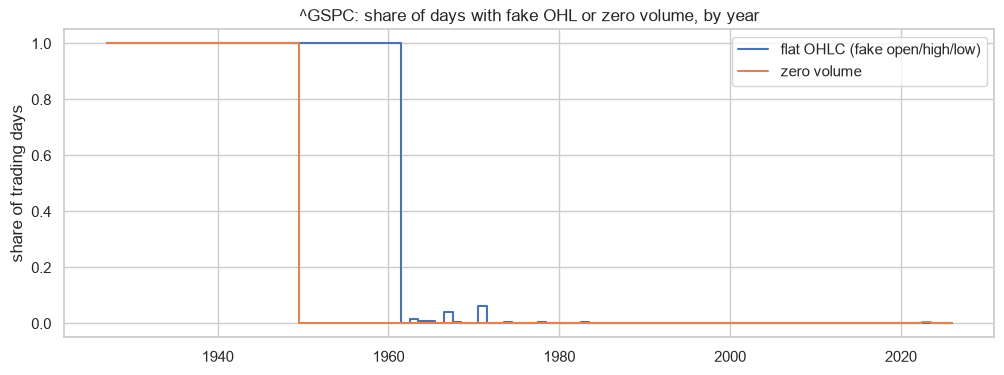

In [9]:
g_ = raw['gspc']
flat = (g_['open'] == g_['high']) & (g_['high'] == g_['low']) & (g_['low'] == g_['close'])
by_year = pd.DataFrame({
    'flat OHLC (fake open/high/low)': flat.groupby(g_.index.year).mean(),
    'zero volume': (g_['volume'] <= 0).groupby(g_.index.year).mean(),
})
fig, ax = plt.subplots()
by_year.plot(ax=ax, drawstyle='steps-mid')
ax.set_ylabel('share of trading days')
ax.set_title('^GSPC: share of days with fake OHL or zero volume, by year')
ax.set_xlabel('')
save(fig, 'du_gspc_flat_ohlc_volume')
print('flat rows before 1962:', int(flat[:'1961'].sum()), ' after:', int(flat['1962':].sum()))
print('zero-volume rows before 1950:', int((g_['volume'] <= 0)[:'1949'].sum()),
      ' after:', int((g_['volume'] <= 0)['1950':].sum()))

In [10]:
# ES: rows where the close lies outside the day's high-low range
es = raw['es']
bad = (es['close'] > es['high'] * 1.0001) | (es['close'] < es['low'] * 0.9999)
t = es.loc[bad, ['open', 'high', 'low', 'close', 'volume']].copy()
t['quarterly expiry Friday?'] = [(d.month in (3, 6, 9, 12)) and d.weekday() == 4 and 15 <= d.day <= 21
                                  for d in t.index]
t

,open,high,low,close,volume,quarterly expiry Friday?
date,,,,,,
2002-01-31,1115.50,1130.00,1113.00,1130.5000,232762,False
2004-03-19,1124.75,1128.00,1122.00,1120.1801,649991,True
2004-12-17,1203.50,1206.75,1193.50,1190.4500,821953,True
2005-06-17,1210.50,1217.50,1210.00,1222.6801,802869,True
2006-03-17,1303.50,1309.00,1303.50,1310.1600,603136,True
2007-09-21,1519.75,1532.25,1516.50,1533.3800,1346720,True
2008-03-18,1279.75,1292.50,1278.00,1332.5000,753289,False
2008-09-19,1201.00,1263.00,1197.25,1279.3101,4007416,True
2010-03-19,1166.25,1170.00,1164.75,1172.9500,2165925,True


**Findings:**
- **No impossible values:** no zero or negative prices, and no high < low in any series.
- **`^GSPC` open/high/low are fake before 1962:** 8,509 rows before 1962-01-02 have O = H = L = C. Another 38 flat days are scattered through 1962–1983. Range-based volatility (Parkinson, Garman-Klass) and overnight gaps can only start in 1962.
- **`^GSPC` volume is zero before 1950** (5,496 days) and on 1 later day. Index "volume" is also not a traded quantity, so we use **SPY volume** (from 1993) as the trading-activity feature instead.
- **`^SP500TR` OHL is unreliable until 2010** (flat rows continue sporadically to 2021), and it has **no volume at all**. Only its close is used.
- **ES has 10 rows where the close lies outside the high-low range.** 8 of them are on quarterly **expiry Fridays**, where Yahoo's splice takes the close from a different contract than the high/low. Only ES close-to-close returns are used, so this doesn't affect the features.

### 2.3 Outliers: are the extreme moves real?

In [11]:
MOVES = {
    '1987-10-19': 'Black Monday 1987',
    '1933-03-15': 'Reopening after the 1933 bank holiday',
    '1929-10-28': 'Black Monday 1929 (Wall Street Crash)',
    '1929-10-29': 'Black Tuesday 1929',
    '1929-10-30': 'Rebound after the 1929 crash',
    '1931-10-06': 'Rally on Hoover banking plan',
    '2020-03-16': 'COVID-19 crash (circuit breaker)',
    '2020-03-12': 'COVID-19 crash (circuit breaker)',
    '2020-03-24': 'COVID-19 stimulus rally',
    '2008-10-13': 'Global financial crisis: bank rescue rally',
    '2008-10-28': 'Global financial crisis rally',
    '2008-10-15': 'Global financial crisis sell-off',
    '2025-04-09': 'Tariff pause rally',
    '1939-09-05': 'Rally after outbreak of World War II',
    '1929-11-06': 'Crash continues',
    '1935-04-16': '?? no known event, reversed next day (see 2.4)',
}
r = np.log(raw['gspc']['close']).diff()
top = r.loc[r.abs().nlargest(12).index].to_frame('log return')
top['simple return'] = np.expm1(top['log return'])
top['event'] = [MOVES.get(str(d.date()), '') for d in top.index]
top['log return'] = top['log return'].round(3)
top['simple return'] = (top['simple return'] * 100).round(1).astype(str) + '%'
top

,log return,simple return,event
date,,,
1987-10-19,-0.229,-20.5%,Black Monday 1987
1933-03-15,0.154,16.6%,Reopening after the 1933 bank holiday
1929-10-28,-0.139,-12.9%,Black Monday 1929 (Wall Street Crash)
2020-03-16,-0.128,-12.0%,COVID-19 crash (circuit breaker)
1929-10-30,0.118,12.5%,Rebound after the 1929 crash
1931-10-06,0.117,12.4%,Rally on Hoover banking plan
1939-09-05,0.112,11.9%,Rally after outbreak of World War II
1932-09-21,0.112,11.8%,
2008-10-13,0.110,11.6%,Global financial crisis: bank rescue rally


In [12]:
ret = r.dropna()
z = (ret - ret.mean()) / ret.std()
print(f'daily moves beyond 5 standard deviations: {int((z.abs() > 5).sum())} '
      f'(a normal distribution would expect {len(ret) * 2 * 2.87e-7:.3f})')
print(f'excess kurtosis: {ret.kurt():.1f}')

daily moves beyond 5 standard deviations: 110 (a normal distribution would expect 0.014)
excess kurtosis: 18.8


**Finding:** almost every extreme move lines up with a documented market event (1929 crash, 1933 reopening, Black Monday 1987, 2008, COVID 2020). Those are real and **must be kept**. The exception is **1935-04-16**: a −10.5% day with no known event, fully reversed the next day. Section 2.4 looks at this kind of case.

Daily returns have very fat tails: excess kurtosis ≈ 19, and 110 moves beyond 5 standard deviations, where a normal distribution would expect 0.01. This matters later: use robust scaling, and prefer models that don't assume normal returns.

### 2.4 Suspected bad prints

A **bad print** is a wrong price in the history, such as a typo. It shows up as a one-day spike that fully reverses the next day. Real markets also whipsaw, but real reversals of this size happen when the market is **already volatile** (October 1929, March 2020). A bad print sits in an otherwise calm market.

So each candidate spike (a > 3% move reversed the next day) is scored against the **previous 3 months' volatility**:

- **Flagged** if both days are ≥ 5 and ≥ 4.5 standard deviations of recent volatility, **and** no other source confirms the move.
- From 1988 onward, the total return index, SPY and ES act as independent confirmation. Before 1988, `^GSPC` is the only source. (Stooq, a possible second source, now blocks scripted downloads.)

In [13]:
from sp500.data_prep import find_bad_prints

c = raw['gspc']['close']
r = np.log(c).diff()
nxt = r.shift(-1)
prior_vol = r.rolling(63).std().shift(1)
cand = ((r.abs() > 0.03) & (nxt.abs() > 0.03) & (np.sign(r) != np.sign(nxt))
        & ((r + nxt).abs() < 0.25 * r.abs()))
others = tuple(daily[col] for col in ('sp500tr_close', 'spy_close', 'es_close'))
flagged = find_bad_prints(c, tuple(o.reindex(c.index) for o in others))

spikes = pd.DataFrame({
    'prev close': c.shift(1), 'close': c, 'next close': c.shift(-1),
    'move': np.expm1(r).mul(100).round(1).astype(str) + '%',
    'next day': np.expm1(nxt).mul(100).round(1).astype(str) + '%',
    'size vs recent vol (sd)': (r.abs() / prior_vol).round(1),
    'other sources?': ['yes' if d >= pd.Timestamp('1988-01-04') else 'no' for d in c.index],
    'flagged as bad print': flagged,
})[cand].sort_values('size vs recent vol (sd)', ascending=False)
print(f'{int(cand.sum())} reversal spikes > 3%, {int(flagged.sum())} flagged as suspected bad prints')
spikes.head(10)

39 reversal spikes > 3%, 4 flagged as suspected bad prints


,prev close,close,next close,move,next day,size vs recent vol (sd),other sources?,flagged as bad print
date,,,,,,,,
1935-04-16,9.1300,8.2200,9.0100,-10.0%,9.6%,8.2,no,True
1961-04-17,66.3700,68.6800,66.2000,3.5%,-3.6%,7.1,no,True
1936-09-16,15.9300,15.0000,15.8700,-5.8%,5.8%,6.4,no,True
1935-08-16,11.5400,10.6200,11.4200,-8.0%,7.5%,5.5,no,True
2020-03-12,2741.3799,2480.6399,2711.0200,-9.5%,9.3%,5.2,yes,False
1931-10-05,9.7000,8.8200,9.9100,-9.1%,12.4%,4.2,no,False
1929-10-29,22.7400,20.4300,22.9900,-10.2%,12.5%,4.1,no,False
1938-10-10,12.8500,13.9100,12.8400,8.2%,-7.7%,3.8,no,False
1931-09-23,10.8000,11.5200,10.6800,6.7%,-7.3%,3.6,no,False


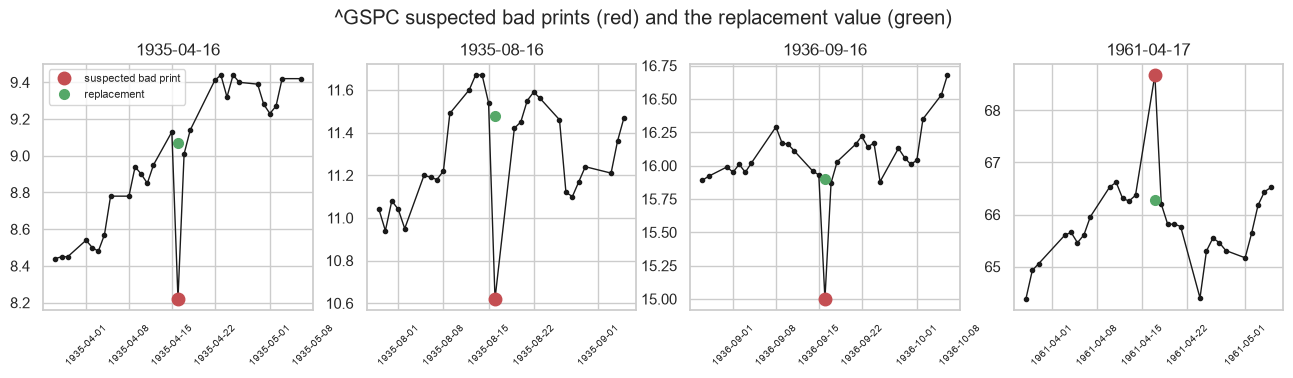

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, d in zip(axes, c.index[flagged]):
    window = c.loc[d - pd.Timedelta(days=20): d + pd.Timedelta(days=20)]
    ax.plot(window.index, window.values, marker='.', color='k', lw=1)
    ax.plot(d, c.loc[d], 'o', color='C3', ms=9, label='suspected bad print')
    fixed = np.sqrt(c.shift(1).loc[d] * c.shift(-1).loc[d])
    ax.plot(d, fixed, 'o', color='C2', ms=7, label='replacement')
    ax.set_title(str(d.date()))
    ax.set_xlabel('')
    ax.tick_params(axis='x', labelrotation=45, labelsize=7)
axes[0].legend(fontsize=8)
fig.suptitle('^GSPC suspected bad prints (red) and the replacement value (green)', y=1.05)
save(fig, 'du_bad_prints')

**Finding:** the rule flags **4 days**: 1935-04-16, 1935-08-16, 1936-09-16 and 1961-04-17. Each is a 5.5–8.2 standard-deviation spike in a calm market, with no matching historical event, and the price returns to its old level the next day.

The next-largest candidate, **2020-03-12** (−10%), scores 5.2 but is **confirmed** by SPY, ES and the total-return index, so it's correctly left alone.

**Cleaning action:** the 4 closes are replaced with the geometric midpoint of the neighbouring closes, and flagged in `gspc_bad_print_fixed`. Without this fix, each spike would inflate 21-day realized volatility for a month and could create fake "stressed" episodes in the labels.

*Caveat:* with no second source before 1988, these are **suspected** errors, not proven ones. The rule and its thresholds are documented, and the flag column makes the change reversible.

## 3. Cross-source consistency

The four series track the same underlying market, so they should agree closely. Where they don't, the difference has to be explainable.

common period: 2000-09-19 -> 2026-10-23 (6,563 days)


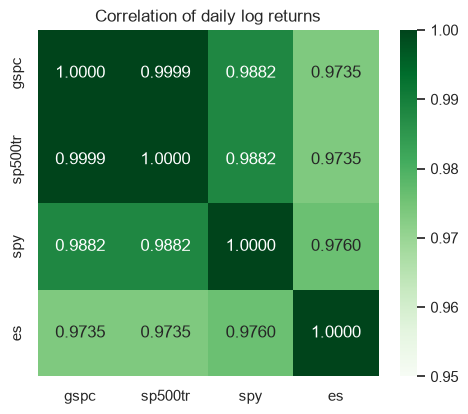

In [15]:
rets = np.log(daily[[f'{n}_close' for n in NAMES]]).diff()
rets.columns = list(NAMES)
common = rets.loc['2000-09-19':].dropna()
print(f'common period: {common.index.min().date()} -> {common.index.max().date()} ({len(common):,} days)')
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(common.corr(), annot=True, fmt='.4f', cmap='Greens', vmin=0.95, vmax=1, ax=ax)
ax.set_title('Correlation of daily log returns')
save(fig, 'du_return_correlation')

1988-2026 annual growth: total return 11.44%, price 9.14% -> dividends add 2.30% a year
SPY (adjusted) vs total return index: -0.12% a year (SPY expense ratio is 0.0945%; the rest is cash drag and timing)


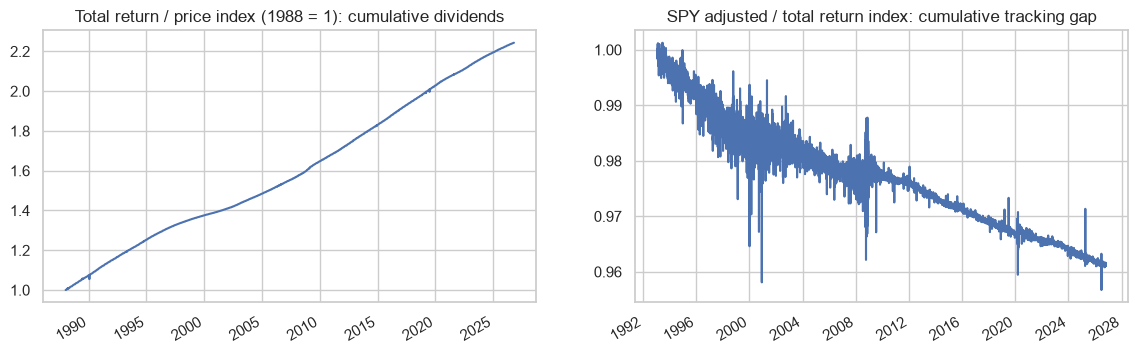

In [16]:
# Total return vs price index: the gap should be the dividend yield
tr = daily['sp500tr_close'].dropna()
px = daily.loc[tr.index, 'gspc_close']
years = (tr.index[-1] - tr.index[0]).days / 365.25
cagr_tr = (tr.iloc[-1] / tr.iloc[0]) ** (1 / years) - 1
cagr_px = (px.iloc[-1] / px.iloc[0]) ** (1 / years) - 1
print(f'1988-2026 annual growth: total return {cagr_tr:.2%}, price {cagr_px:.2%} '
      f'-> dividends add {cagr_tr - cagr_px:.2%} a year')

# SPY (dividend-adjusted) vs total return index: the gap should be about the ETF's costs
d = (np.log(daily['spy_adj_close']).diff() - np.log(daily['sp500tr_close']).diff()).dropna()
spy_years = (d.index[-1] - d.index[0]).days / 365.25
print(f'SPY (adjusted) vs total return index: {d.sum() / spy_years:+.2%} a year '
      f'(SPY expense ratio is 0.0945%; the rest is cash drag and timing)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
((tr / tr.iloc[0]) / (px / px.iloc[0])).plot(ax=axes[0])
axes[0].set_title('Total return / price index (1988 = 1): cumulative dividends')
np.exp(d.cumsum()).plot(ax=axes[1])
axes[1].set_title('SPY adjusted / total return index: cumulative tracking gap')
for ax in axes:
    ax.set_xlabel('')
save(fig, 'du_dividends_tracking')

In [17]:
# ES futures vs index: are the quarterly roll days visibly different?
gap = (np.log(daily['es_close']).diff() - np.log(daily['gspc_close']).diff()).dropna()
roll = daily.loc[gap.index, 'es_roll_window'] == 1
print(pd.DataFrame({
    'mean |ES return - index return|': [gap[roll].abs().mean(), gap[~roll].abs().mean()],
    'days': [int(roll.sum()), int((~roll).sum())],
}, index=['roll window', 'other days']).to_string(float_format=lambda x: f'{x:.5f}'))
print('\nlargest ES-vs-index daily gaps:')
print(gap.abs().nlargest(6).round(4).to_string())

             mean |ES return - index return|  days
roll window                          0.00118   522
other days                           0.00143  6041

largest ES-vs-index daily gaps:
date
2020-03-23    0.0637
2020-03-20    0.0587
2009-03-23    0.0337
2001-09-24    0.0314
2009-03-20    0.0265
2008-09-19    0.0260


**Findings:**
- **All four sources agree:** daily return correlations are 0.97–1.00. The total return and price index move almost identically day to day (0.9996).
- **The gaps match theory:** total return beats price by about **2.3% a year**, which is the S&P 500 dividend yield over 1988–2026. SPY's adjusted price trails the total-return index by about **0.12% a year**, close to its 0.0945% expense ratio. This confirms the dividend adjustment in `spy.adj_close` and the TR series are correct.
- **ES roll jumps are not visible** in Yahoo's continuous series: the ES-vs-index gap is no larger in roll windows than on other days. The biggest gaps come from **closing-time differences** (ES settles after the 4 pm stock close) on very volatile days, such as March 2020 and March 2009. Masking roll windows is kept as a cheap precaution, but it isn't critical.

## 4. Effect of cleaning

Cleaning rules (`src/sp500/data_prep.py`):
1. Remove duplicate dates and sort.
2. Non-positive prices → NaN (none found).
3. Flat OHLC rows → open/high/low set to NaN (the close is kept).
4. Zero volume → NaN.
5. Align on the `^GSPC` calendar: extra ES holiday sessions are dropped, and missing days are forward-filled for **prices only, at most 2 days, only for days the series has no row for**.
6. Suspected bad prints in `^GSPC` (section 2.4) → close replaced by the geometric midpoint of its neighbours; flagged in `gspc_bad_print_fixed`.
7. Flag ES roll windows (`es_roll_window`).

In [18]:
quality.set_index('series')

,rows,start,end,non_positive_prices,flat_ohlc_rows,inconsistent_hlc_rows,zero_volume_rows,missing_close,moves_gt_15pct,largest_up_move,largest_down_move,largest_down_date,bad_prints_fixed
series,,,,,,,,,,,,,
gspc,24821,1927-12-30,2026-10-23,0,8547,0,5497,0,2,0.153661,-0.228997,1987-10-19,4
sp500tr,9776,1988-01-04,2026-10-23,0,5379,0,9776,0,0,0.109582,-0.127605,2020-03-16,0
spy,8492,1993-01-29,2026-10-23,0,0,0,0,0,0,0.135577,-0.115887,2020-03-16,0
es,6590,2000-09-18,2026-10-23,0,0,10,11,0,0,0.132022,-0.109552,2020-03-16,0


In [19]:
rows = []
for n, df in raw.items():
    inside = (daily.index >= df.index.min()) & (daily.index <= df.index.max())
    for field in ['close', 'open', 'volume']:
        rows.append({
            'series': n, 'field': field,
            'raw rows': len(df),
            'usable after cleaning': int(daily.loc[inside, f'{n}_{field}'].notna().sum()),
        })
usable_after = pd.DataFrame(rows).pivot(index='series', columns='field', values='usable after cleaning')
usable_after.insert(0, 'raw rows', [len(raw[n]) for n in usable_after.index])
usable_after

field,raw rows,close,open,volume
series,,,,
es,6590,6564,6564,6553
gspc,24821,24821,16274,19324
sp500tr,9776,9776,4397,0
spy,8492,8492,8492,8492


In [20]:
# Sanity checks on the cleaned table
g_flat = (raw['gspc']['open'] == raw['gspc']['close']) & (raw['gspc']['high'] == raw['gspc']['low']) \
         & (raw['gspc']['open'] == raw['gspc']['high'])
checks = {
    'every fake OHL row is NaN after cleaning': bool(daily.loc[g_flat[g_flat].index, 'gspc_open'].isna().all()),
    'no real OHL row was blanked': int(daily['gspc_open'].isna().sum()) == int(g_flat.sum()),
    'dates unique and sorted': daily.index.is_unique and daily.index.is_monotonic_increasing,
    'gspc close complete': bool(daily['gspc_close'].notna().all()),
    'bad prints fixed (and flagged)': int(daily['gspc_bad_print_fixed'].sum()),
    'largest cleaned daily move': f"{np.expm1(np.log(daily['gspc_close']).diff()).abs().max():.1%} (1987-10-19)",
    'ES rows filled in from neighbours': int(daily['es_close'].notna().sum() - len(es.index.intersection(CAL))),
}
pd.Series(checks, name='result').to_frame()

,result
every fake OHL row is NaN after cleaning,True
no real OHL row was blanked,True
dates unique and sorted,True
gspc close complete,True
bad prints fixed (and flagged),4
largest cleaned daily move,20.5% (1987-10-19)
ES rows filled in from neighbours,2


## 5. Conclusions for the next phases

| # | Finding | Consequence |
|---|---|---|
| 1 | `^GSPC` close is complete from 1927-12-30 to 2026-10-23 (24,821 days). Extreme moves are real events, **except 4 suspected bad prints** (1935–1961) | Bad prints fixed and flagged. Usable for **labels** over the full history. Keep real outliers; use robust scaling |
| 2 | Real open/high/low only from **1962**; index volume only from **1950**; SPY volume from **1993** | Range-based volatility and gap features start in 1962. Volume features start in 1993. Models using them must start then, or treat the features as missing |
| 3 | Total return index only from **1988**, and only its close is usable | Bull/bear labels splice the price index (before 1988) with total return (after) |
| 4 | Sources agree (correlations ≥ 0.97); dividend (+2.3%/yr) and ETF-cost (−0.12%/yr) gaps match theory | The data is internally consistent. No source needs correcting |
| 5 | ES closes after the index, so ES-vs-index gaps reflect late-day news; roll jumps aren't visible | ES returns can be used as a "late news" feature from 2000; roll masking is optional |
| 6 | Calendar has no Saturdays (pre-1952) and some long closures (1933, 2001, 2012) | A few daily returns span several days. A minor effect; no action needed |
| 7 | Fat tails (excess kurtosis ≈ 19) | Avoid methods that assume normal returns; check model behavior in crashes |

**Changes to cleaning made because of this analysis:**
1. **Bad-print rule added** (section 2.4): 4 `^GSPC` closes fixed and flagged.
2. **Forward-fill bug fixed:** the alignment step had been re-filling 16 deliberately blanked post-1962 OHL values. It now fills only days a series is actually missing from the calendar.